In [1]:
import numpy as np
A = np.array([
    [2.1, 8.2, 3.1, 7.0, 4.2],
    [1.8, 7.5, 2.7, 6.8, 3.9],
    [2.5, 8.7, 3.4, 7.6, 4.5],
    [2.2, 7.9, 3.6, 6.5, 4.1],
    [1.7, 8.4, 2.9, 7.3, 3.7],
    [2.8, 7.7, 3.2, 6.9, 4.6],
    [2.0, 8.9, 3.7, 7.8, 4.0],
    [2.4, 8.1, 2.8, 6.7, 4.4],
    [1.9, 7.8, 3.3, 7.5, 3.8],
    [2.6, 8.5, 3.0, 7.1, 4.3]
])

B = np.array([
    [8.1, 2.1, 7.2, 3.0, 8.3],
    [7.6, 1.8, 6.8, 3.4, 7.9],
    [8.7, 2.5, 7.5, 2.7, 8.8],
    [8.2, 2.2, 6.9, 3.6, 8.1],
    [7.9, 1.7, 7.8, 3.1, 8.5],
    [8.5, 2.8, 7.1, 2.9, 7.7],
    [7.7, 2.0, 7.4, 3.7, 8.9],
    [8.9, 2.4, 6.7, 3.2, 8.2],
    [8.3, 1.9, 7.7, 2.8, 7.8],
    [7.8, 2.6, 7.0, 3.5, 8.6]
])


In [2]:
from angular_excess import exceso_gradiente_proyectado_optimizado as grad_proy

In [19]:
n = A.shape[0]
tiempos = []
iteraciones = []
cosenos = []
U_opt = []
for i in range(100):
    print("="*30)
    print("iter n:", (i+1))
    x_rand = np.random.rand(n)
    print(x_rand)
    results = grad_proy(A.T, B.T, x0 = x_rand, t=0.1, max_iter=1000, eps=1e-5)
    tiempos.append(results['tiempo_final'])
    iteraciones.append(results['k'])
    cosenos.append(results['coseno'])
    print(results['u_opt'])
    U_opt.append(results['u_opt'])
    for k,v in results.items():
        print( f"- {k}: {v}")
        # print("-"*20 + "\n")

iter n: 1
[0.25295533 0.34114201 0.35536168 0.82519963 0.31698743 0.08873405
 0.7235506  0.72519544 0.35644101 0.42079586]
[0.13934426 0.68852459 0.23770492 0.59836066 0.30327869]
- u_opt: [0.13934426 0.68852459 0.23770492 0.59836066 0.30327869]
- v_opt: [0.54770905 0.18256968 0.49153377 0.24576688 0.60388434]
- coseno: 0.6490663095755653
- angulo: 0.8644398918536238
- tiempo_final: 0.0007800000021234155
- k: 2
- converged: True
- valores_normas: [np.float64(0.06346670102905563)]
iter n: 2
[0.098886   0.11068517 0.6030551  0.96850718 0.06609538 0.12700081
 0.55499047 0.6958514  0.37123774 0.76638413]
[0.13934426 0.68852459 0.23770492 0.59836066 0.30327869]
- u_opt: [0.13934426 0.68852459 0.23770492 0.59836066 0.30327869]
- v_opt: [0.54770905 0.18256968 0.49153377 0.24576688 0.60388434]
- coseno: 0.6490663095755653
- angulo: 0.8644398918536238
- tiempo_final: 0.0008264000061899424
- k: 3
- converged: True
- valores_normas: [np.float64(0.07095940964367076), np.float64(0.00220273818452426

In [25]:
U_opt = np.array(U_opt)
diferencias_uopt = np.linalg.norm(U_opt[1:] - U_opt[:-1], axis=1)
diferencias_uopt = np.insert(diferencias_uopt, 0, 0)  # Insertar un cero al inicio para mantener la misma longitud

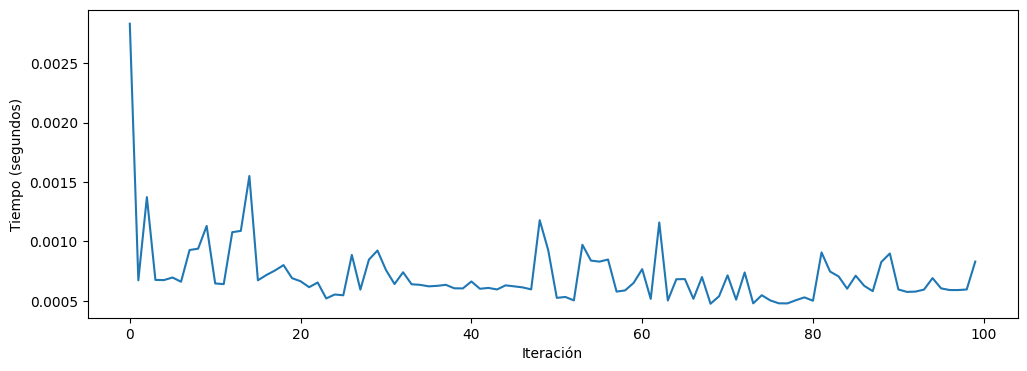

In [6]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 4))
plt.plot(np.arange(100), tiempos, label='Tiempo de ejecución')
plt.xlabel('Iteración')
plt.ylabel('Tiempo (segundos)')
plt.show()

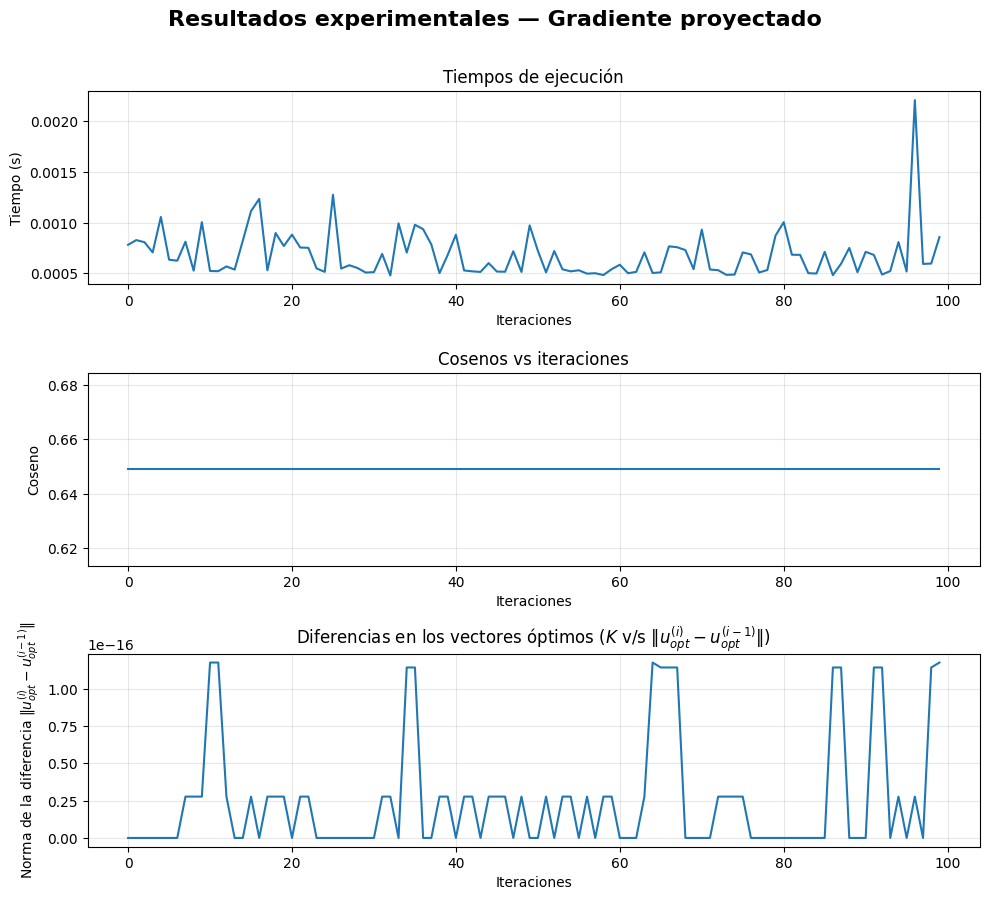

In [32]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9))

fig.suptitle(
    "Resultados experimentales — Gradiente proyectado",
    fontsize=16,
    fontweight="bold",
    y=0.995
)


ax[0].plot(np.arange(100), tiempos, label='Tiempo de ejecución')
ax[0].set_title(
    "Tiempos de ejecución"
)
ax[0].set_xlabel("Iteraciones")
ax[0].set_ylabel("Tiempo (s)")



ax[1].plot(np.arange(100), cosenos, label='coseno')
ax[1].set_title("Cosenos vs iteraciones")
ax[1].set_xlabel("Iteraciones")
ax[1].set_ylabel("Coseno")

ax[2].plot(np.arange(100), diferencias_uopt, label='Diferencias')
ax[2].set_title(rf"Diferencias en los vectores óptimos ($K$ v/s $\|u_{{opt}}^{{(i)}} - u_{{opt}}^{{(i-1)}}\|$)")
ax[2].set_xlabel("Iteraciones")
ax[2].set_ylabel(rf"Norma de la diferencia $\|u_{{opt}}^{{(i)}} - u_{{opt}}^{{(i-1)}}\|$")

# # 3. Iteraciones por ejecución
# ax[2].plot(np.arange(100), cosenos, label='coseno')
# ax[2].set_title("Cosenos vs iteraciones")
# ax[2].set_xlabel("Iteraciones")
# ax[2].set_ylabel("Coseno")

# # 4. Distribución del coseno normalizado
# cosenos = df_ok["coseno_normalizado"].dropna()

# ax[3].hist(cosenos, bins=15, edgecolor="black")
# ax[3].set_title("Distribución del coseno entre los vectores óptimos")
# ax[3].set_xlabel(r"$\cos(\theta)$")
# ax[3].set_ylabel("Frecuencia")

# # 5. Distribución de ángulos
# angulos = df_ok["angulo_deg"].dropna()

# ax[4].hist(angulos, bins=15, edgecolor="black")
# ax[4].set_title("Distribución del ángulo entre los vectores óptimos")
# ax[4].set_xlabel("Ángulo (grados)")
# ax[4].set_ylabel("Frecuencia")

# # 6. Relación entre iteraciones y tiempo
# df_scatter = df.dropna(
#     subset=["k", "tiempo_algoritmo_s"]
# )

# ax[5].scatter(
#     df_scatter["k"],
#     df_scatter["tiempo_algoritmo_s"]
# )
# ax[5].set_title("Relación entre iteraciones y tiempo de ejecución")
# ax[5].set_xlabel("Iteraciones")
# ax[5].set_ylabel("Tiempo (s)")

# Formato general
for eje in ax:
    eje.grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

In [15]:
help(np.random.rand)

Help on method rand in module numpy.random:

rand(*args) method of numpy.random.mtrand.RandomState instance
    rand(d0, d1, ..., dn)
    
    Random values in a given shape.
    
    .. note::
        This is a convenience function for users porting code from Matlab,
        and wraps `random_sample`. That function takes a
        tuple to specify the size of the output, which is consistent with
        other NumPy functions like `numpy.zeros` and `numpy.ones`.
    
    Create an array of the given shape and populate it with
    random samples from a uniform distribution
    over ``[0, 1)``.
    
    Parameters
    ----------
    d0, d1, ..., dn : int, optional
        The dimensions of the returned array, must be non-negative.
        If no argument is given a single Python float is returned.
    
    Returns
    -------
    out : ndarray, shape ``(d0, d1, ..., dn)``
        Random values.
    
    See Also
    --------
    random
    
    Examples
    --------
    >>> np.random.rand

In [67]:
def geodesica(u,v,t):
    alfa = np.arccos(np.clip(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v)), -1.0, 1.0))
    return np.sin(alfa * t) / np.sin(alfa) * u + np.sin(alfa * (1 - t)) / np.sin(alfa) * v

def matriz_schur_identidad(n):
  ident = np.eye(n)
  schur = ident[:,0] - ident[:,1]
  for i in range(1,n-1):
    schur = np.vstack((schur, ident[:,i] - ident[:,i+1]))
  schur = schur.T
  return schur/np.linalg.norm(schur, axis = 0 , keepdims=True), np.eye(n)

s , i = matriz_schur_identidad(3)


In [68]:
import numpy as np
import time
from scipy.optimize import minimize, nnls
def problema_polar(G,H):
    # G,H son matrices de generadores de los conos P y Q respectivamente.
    n = G.shape[0]
    iterados = []
    def callback(z):
        iterados.append(z.copy())
    def constraint_GH(z , G, H):
        # desigualdad
        t = z[0]
        x = z[1:]
        return -((H.T@G)@x - t)
    def constraint_x(z):
        # desigualdad
        x = z[1:]
        return x
    def constraint_norm(z,G):
        # desgualdad
        return -(np.linalg.norm(G@z[1:])**2 - 1)

    def f_objetivo(z):
        return z[0]  # minimizar t
    z0 = np.ones(n+1)  # punto inicial (t, x)

    restricciones = [
        {'type': 'ineq', 'fun': constraint_GH, 'args':(G,H)},
        {'type': 'ineq', 'fun': constraint_x},
        {'type': 'ineq', 'fun': constraint_norm, 'args':(G,)},
    ]
    result = minimize(f_objetivo, z0, method='SLSQP', constraints=restricciones, callback=callback)
    t_opt = result.x[0]
    x_opt = result.x[1:]
    distancias = [
        np.linalg.norm(iterados[k+1] - iterados[k])
        for k in range(len(iterados)-1)
    ]
    return t_opt, x_opt, distancias

def proj_cone(G, u):
    """
    Proyecta el vector u sobre el cono convexo P = cone(G)
    mediante mínimos cuadrados no negativos (equivalente a lsqnonneg en MATLAB).
    """
    x, _ = nnls(G, u)
    return G @ x
def es_polar(u,H, tol = 1e-8):
    return np.all(H.T @ u <= tol)
def f_obj(u, H):
    return np.linalg.norm(proj_cone(H, u))
def gradiente(u, H):
    projuQ = proj_cone(H, u)
    norma_projuQ = np.linalg.norm(projuQ)
    if norma_projuQ < 1e-12:
        return np.zeros_like(u)
    else:
        return projuQ / norma_projuQ
def linesearch(u, g, H, t0=1.0, alpha=0.5, beta=0.5):
    t = t0
    while f_obj(u - t * g, H) > f_obj(u, H) - alpha * t * np.dot(g, g):
        t *= beta
    return t
def exceso_gradiente_proyectado_optimizado(G, H, u0, t = 0.1, max_iter=1000, eps=1e-5):
    G = G / np.linalg.norm(G, axis=0, keepdims=True)
    H = H / np.linalg.norm(H, axis=0, keepdims=True)
    n = G.shape[0]
    p = G.shape[1]
    q = H.shape[1]
    # if x0 is None:
    #     u0 = G@np.ones(p)
    # else: 
    #     u0 = G@x0
    # u0 = u0 / np.linalg.norm(u0)
    u_curr = u0.copy()
    valores_normas = []
    # bucle 
    converged = False
    tiempo = time.perf_counter()
    t_act = t
    for k in range(1, max_iter + 1):
        # verificar si es polar o no 
        if es_polar(u_curr,H):
            t_opt, u_opt, distancias = problema_polar(G,H)
            valores_normas += distancias
            converged = True
            break
            
        # de no ser polar, inicia el descenso proyectado
        projuQ = proj_cone(H, u_curr)
        norma_projuQ = np.linalg.norm(projuQ)
        # gradiente
        if norma_projuQ < 1e-12:
            g = np.zeros(n)
        else:
            g = gradiente(u_curr, H)
        # Paso euclideo directo en R^n
        t_k = max(t_act , 1e-6)  # Evitar pasos demasiado pequeños
        t_act = linesearch(u_curr, g, H, t0 = t_k)
        us = u_curr - t_act * g
        # Proy. sobre el cono P y retracción (normalización)
        projuP = proj_cone(G, us)
        norm_projuP = np.linalg.norm(projuP)
        
        if norm_projuP < 1e-12:
            u_update = u_curr.copy()
        else:
            u_update = projuP / norm_projuP
            
        if np.linalg.norm(u_update - u_curr) < eps:
            converged = True
            u_opt = u_update
            break
        valores_normas.append(np.linalg.norm(u_update - u_curr))
        u_curr = u_update
    v_opt = proj_cone(H, u_curr)/np.linalg.norm(proj_cone(H, u_curr))
    tiempo_final = time.perf_counter() - tiempo
    resultados = {"u_opt": u_opt, "v_opt": v_opt,"coseno" :np.dot(v_opt, u_opt) , 
            "angulo": np.arccos(np.clip(np.dot(v_opt, u_opt), -1, 1)), 
            "tiempo_final": tiempo_final, "k": k, "converged": converged,
              "valores_normas": valores_normas}
    return resultados

In [74]:
r = exceso_gradiente_proyectado_optimizado(s,i, u0 = np.array([0.7741, -.6119,-.1622]), t = 0.1, max_iter=1000, eps=1e-5)
r['u_opt'], r['v_opt'], r['coseno']

(array([ 0.70710678, -0.70710678,  0.        ]),
 array([1., 0., 0.]),
 np.float64(0.7071067811865475))

In [73]:
r = exceso_gradiente_proyectado_optimizado(s,i, u0 = np.array([0.7256, -.0385,-.6871]), t = 0.1, max_iter=1000, eps=1e-5)
r['u_opt'], r['v_opt'], r['coseno']

(array([ 0.4082943 ,  0.40820228, -0.81649658]),
 array([0.70719759, 0.70701596, 0.        ]),
 np.float64(0.5773502715624077))

In [ ]:
import numpy as np
import time


def exceso_gradiente_ruido(G,H,u0=None,eta=0.1,sigma0=0.05,decay_ruido=0.001,max_iter=5000,eps=1e-6,ventana=30,factor_escape=5.0,random_state=None,tol_polar=1e-8 )

"""
    Descenso proyectado con ruido gaussiano.

    Minimiza aproximadamente:
        F(u) = 0.5 * ||Proj_Q(u)||^2

    sujeto a:
        u pertenece a P
        ||u|| = 1

    El ruido se agrega a la actualización, no a los
    generadores de los conos.

    Si detecta estancamiento, aumenta temporalmente
    la intensidad del ruido.

    Requiere las funciones:
        proj_cone(G, u)
        es_polar(u, H, tol)
    """

    inicio = time.perf_counter()
    rng = np.random.default_rng(random_state)

    G = np.asarray(G, dtype=float).copy()
    H = np.asarray(H, dtype=float).copy()

    if G.ndim != 2 or H.ndim != 2:
        raise ValueError("G y H deben ser matrices bidimensionales.")

    if G.shape[0] != H.shape[0]:
        raise ValueError("G y H deben tener el mismo número de filas.")

    if G.shape[1] == 0 or H.shape[1] == 0:
        raise ValueError("Los conos deben tener generadores.")

    if not np.all(np.isfinite(G)) or not np.all(np.isfinite(H)):
        raise ValueError("G y H deben contener valores finitos.")

    if eta <= 0 or sigma0 < 0:
        raise ValueError("eta debe ser positivo y sigma0 no negativo.")

    if decay_ruido < 0 or ventana < 1 or factor_escape < 1:
        raise ValueError("Parámetros de ruido o escape no válidos.")

    if max_iter < 1 or eps <= 0:
        raise ValueError("max_iter debe ser positivo y eps > 0.")

    # Normalizar los generadores sin modificar los conos.
    normas_G = np.linalg.norm(G, axis=0)
    normas_H = np.linalg.norm(H, axis=0)

    if np.any(normas_G < 1e-12) or np.any(normas_H < 1e-12):
        raise ValueError("No se admiten generadores nulos.")

    G /= normas_G
    H /= normas_H

    n, p = G.shape

    # Inicialización.
    if u0 is None:
        u = G @ np.ones(p)
    else:
        u0 = np.asarray(u0, dtype=float)

        if u0.shape != (n,):
            raise ValueError("u0 debe tener longitud igual a G.shape[0].")

        # if np.any(u0 < 0):
        #     raise ValueError("u0 debe ser no negativo.")

        u = u0

    norma_u = np.linalg.norm(u)

    if norma_u < 1e-12:
        raise ValueError("El vector inicial es nulo.")

    u /= norma_u

    # Objetivo completo.
    def objetivo(u):
        proy = proj_cone(H, u)
        return 0.5 * np.dot(proy, proy)

    F = objetivo(u)

    # Mejor solución encontrada.
    u_best = u.copy()
    F_best = F

    # Historiales.
    historial_objetivo = [F]
    historial_ruido = []
    historial_cambios = []

    sin_mejora = 0
    sigma_actual = sigma0

    converged = False
    motivo_parada = "max_iter alcanzado"
    k_final = 0

    for k in range(1, max_iter + 1):

        k_final = k

        # Si se alcanza el cono polar, F(u) = 0:
        # se ha encontrado un mínimo global del objetivo.
        if es_polar(u, H, tol=tol_polar):
            F = 0.0
            F_best = 0.0
            u_best = u.copy()

            converged = True
            motivo_parada = "Se encontró una dirección polar."
            break

        # Gradiente exacto del objetivo cuadrático.
        grad = proj_cone(H, u)

        # Reducir lentamente el ruido.
        sigma_base = sigma0 / (1.0 + decay_ruido * (k - 1))

        # Si hay estancamiento, intensificar las perturbaciones.
        if sin_mejora >= ventana:
            sigma_actual = factor_escape * sigma_base
            sin_mejora = 0
        else:
            sigma_actual = sigma_base

        # Ruido gaussiano en el espacio ambiente R^n.
        ruido = rng.normal(loc=0.0, scale=1.0, size=n)

        # Actualización perturbada.
        u_trial = u - eta * grad + sigma_actual * ruido

        # Proyectar sobre el cono P.
        u_projected = proj_cone(G, u_trial)

        norma_projected = np.linalg.norm(u_projected)

        # Si la proyección es nula, intentar otra perturbación.
        if norma_projected < 1e-12:
            u_trial = u + sigma_actual * ruido
            u_projected = proj_cone(G, u_trial)
            norma_projected = np.linalg.norm(u_projected)

            if norma_projected < 1e-12:
                historial_objetivo.append(F)
                historial_ruido.append(sigma_actual)
                historial_cambios.append(0.0)
                sin_mejora += 1
                continue

        # Normalización: mantener u en P ∩ S^(n-1).
        u_new = u_projected / norma_projected

        # Evaluar el objetivo completo, no una aproximación.
        F_new = objetivo(u_new)

        cambio = np.linalg.norm(u_new - u)

        historial_objetivo.append(F_new)
        historial_ruido.append(sigma_actual)
        historial_cambios.append(cambio)

        # Guardar la mejor solución encontrada.
        if F_new < F_best:
            F_best = F_new
            u_best = u_new.copy()

        # Actualizar la posición actual.
        u = u_new
        F = F_new

        # Reiniciar el contador si hubo una mejora suficiente.
        if F_new < historial_objetivo[-2] - 1e-12:
            sin_mejora = 0
        else:
            sin_mejora += 1

        # Si se alcanza el objetivo cero, no hace falta seguir.
        if es_polar(u, H, tol=tol_polar):
            F_best = 0.0
            u_best = u.copy()

            converged = True
            motivo_parada = "Se encontró una dirección polar."
            break

    # La mejor solución encontrada.
    u_opt = u_best

    proy_Q = proj_cone(H, u_opt)
    norma_proy_Q = np.linalg.norm(proy_Q)

    polar_final = es_polar(u_opt, H, tol=tol_polar)

    if norma_proy_Q > 1e-12:
        v_opt = proy_Q / norma_proy_Q

        coseno = float(
            np.clip(np.dot(u_opt, v_opt), -1.0, 1.0)
        )

        angulo = float(np.arccos(coseno))
    else:
        v_opt = None
        coseno = None
        angulo = None

    tiempo_final = time.perf_counter() - inicio

    return {
        "u_opt": u_opt,
        "u_final": u,
        "v_opt": v_opt,
        "objetivo_final": F_best,
        "coseno": coseno,
        "angulo": angulo,
        "es_polar": polar_final,
        "tiempo_final": tiempo_final,
        "k": k_final,
        "converged": converged,
        "motivo_parada": motivo_parada,
        "historial_objetivo": historial_objetivo,
        "historial_ruido": historial_ruido,
        "historial_cambios": historial_cambios
    }

In [79]:
rn = exceso_gradiente_ruido(s,i, u0 = np.array([0.7256, -.0385,-.6871]))
rn['u_opt'], rn['v_opt'], rn['coseno']

(array([ 0.40824778,  0.4082488 , -0.81649658]),
 array([0.70710589, 0.70710767, 0.        ]),
 0.5773502691899286)

In [ ]:
rn1 = exceso_gradiente_ruido(s,i, u0 = np.array([0.7741, -.6119,-.1622]), sigma0 = 0.1, decay_ruido = 0.001)
rn1['u_opt'], rn1['v_opt'], rn1['coseno']

(array([ 0.40827807,  0.40821851, -0.81649658]),
 array([0.70715836, 0.7070552 , 0.        ]),
 0.5773502702135425)

: 

=== CASO 1: Cono de Schur Estándar vs Cono Identidad ===
Polo SVM e*: [0.57735027 0.57735027 0.57735027]
u* Re-proyectado: [0.70710678 0.70710678 0.        ]
v* Re-proyectado: [0.70710678 0.70710678 0.        ]
Distancia Esférica: 0.000000
(Nota: El cono de Schur está contenido en el cono Identidad, por lo que la distancia es 0).

=== CASO 2: Conos Disjuntos en el Mismo Hemisferio (S^2) ===
Polo Admisible e*:  [0.82594259 0.520841   0.21573941]
u_hat* en H(e,1):    [ 3.27759679 -3.27759679  0.        ]
v_hat* en H(e,1):    [1.21073790e+00 1.49211779e-15 0.00000000e+00]
Distancia en H(e,1): 3.874861
--------------------------------------------------
u* Re-proyectado a S^2: [ 0.70710678 -0.70710678  0.        ]
v* Re-proyectado a S^2: [1.00000000e+00 1.23240363e-15 0.00000000e+00]
Distancia Esférica (Gnomónica): 0.76536686
Distancia Esférica (Directa):   0.76536701
Diferencia / Error Absoluto:    1.48e-07


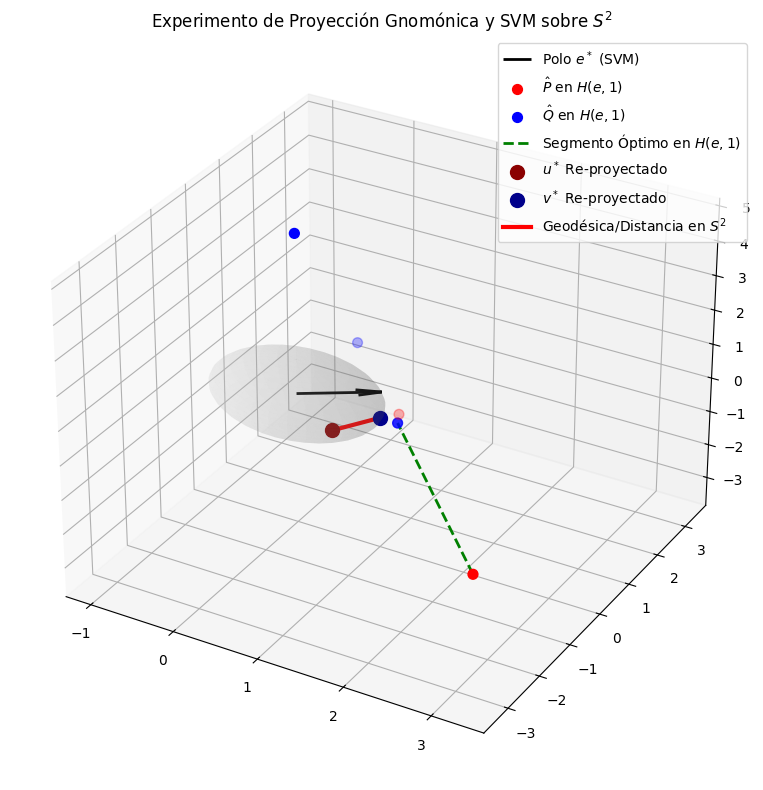

In [76]:
import numpy as np
import scipy.optimize as opt
import matplotlib.pyplot as plt

class GnomonicMaxMinExperiment:
    """
    Experimento para resolver max min ||u - v|| en S^n vía proyección gnomónica
    en el hiperplano tangente H(e,1) derivado por SVM sin sesgo.
    """
    def __init__(self, d=3, P_generators=None, Q_generators=None):
        self.d = d
        
        # 1. Definición de Generadores
        if P_generators is not None:
            self.P_raw = np.array(P_generators, dtype=float)
        else:
            # Cono de Schur estándar (matriz triangular inferior)
            self.P_raw = np.tril(np.ones((d, d)))
            
        if Q_generators is not None:
            self.Q_raw = np.array(Q_generators, dtype=float)
        else:
            # Cono Identidad estándar (base canónica I_d)
            self.Q_raw = np.eye(d)
            
        # Normalización sobre la esfera unitaria S^{d-1}
        self.P_gen = self.P_raw / np.linalg.norm(self.P_raw, axis=1, keepdims=True)
        self.Q_gen = self.Q_raw / np.linalg.norm(self.Q_raw, axis=1, keepdims=True)
        
        self.num_p = self.P_gen.shape[0]
        self.num_q = self.Q_gen.shape[0]
        
        # Variables de estado
        self.w_star = None
        self.e_star = None
        self.P_hat = None
        self.Q_hat = None
        self.u_hat_star = None
        self.v_hat_star = None
        self.u_star = None
        self.v_star = None
        self.gnomonic_dist = None
        self.spherical_dist = None

    def find_admissible_pole_svm(self):
        """
        Calcula el polo óptimo e* resolviendo el problema dual/primal de SVM
        de margen máximo sin término de sesgo (bias=0).
        """
        X = np.vstack([self.P_gen, self.Q_gen])
        
        def objective(w):
            return 0.5 * np.dot(w, w)
        
        def grad_obj(w):
            return w
        
        constraints = {
            'type': 'ineq',
            'fun': lambda w: X @ w - 1.0,
            'jac': lambda w: X
        }
        
        w0 = np.ones(self.d)
        res = opt.minimize(objective, w0, jac=grad_obj, constraints=constraints, method='SLSQP')
        
        if not res.success:
            raise RuntimeError(f"Falló la optimización SVM: {res.message}")
            
        self.w_star = res.x
        self.e_star = self.w_star / np.linalg.norm(self.w_star)
        
        # Verificación de admisibilidad estricta: <x_i, e*> > 0
        margins = X @ self.e_star
        if np.any(margins <= 0):
            raise ValueError("El polo e* no es estrictamente admisible para todos los generadores.")
            
        return self.e_star, margins

    def project_gnomonic(self):
        """
        Proyecta los generadores sobre el hiperplano H(e,1) = {x : <x, e*> = 1}
        g_e(u) = u / <u, e*>
        """
        if self.e_star is None:
            self.find_admissible_pole_svm()
            
        self.P_hat = self.P_gen / (self.P_gen @ self.e_star)[:, None]
        self.Q_hat = self.Q_gen / (self.Q_gen @ self.e_star)[:, None]
        return self.P_hat, self.Q_hat

    def _min_dist_to_Q_hat(self, u_hat):
        """
        Dado u_hat en H(e,1), resuelve el problema convexo interno:
        min_{beta >= 0, sum(beta)=1} || u_hat - sum(beta_j * h_j_hat) ||_2
        """
        def obj(beta):
            v_hat = self.Q_hat.T @ beta
            return np.linalg.norm(u_hat - v_hat)
        
        beta0 = np.ones(self.num_q) / self.num_q
        bounds = [(0, 1)] * self.num_q
        constraints = {'type': 'eq', 'fun': lambda beta: np.sum(beta) - 1.0}
        
        res = opt.minimize(obj, beta0, bounds=bounds, constraints=constraints, method='SLSQP')
        v_hat_opt = self.Q_hat.T @ res.x
        return res.fun, v_hat_opt

    def solve_max_min_gnomonic(self):
        """
        Resuelve el problema max_{u_hat in conv(P_hat)} min_{v_hat in conv(Q_hat)} ||u_hat - v_hat||
        Evaluación sobre los puntos extremales de P_hat.
        """
        if self.P_hat is None:
            self.project_gnomonic()
            
        best_dist = -1.0
        best_u_hat = None
        best_v_hat = None
        
        for i in range(self.num_p):
            u_cand = self.P_hat[i]
            dist_val, v_cand = self._min_dist_to_Q_hat(u_cand)
            if dist_val > best_dist:
                best_dist = dist_val
                best_u_hat = u_cand
                best_v_hat = v_cand
                
        self.gnomonic_dist = best_dist
        self.u_hat_star = best_u_hat
        self.v_hat_star = best_v_hat
        return best_dist, best_u_hat, best_v_hat

    def reproject_to_sphere(self):
        """
        Re-proyección inversa de los óptimos en H(e,1) hacia la esfera S^{d-1}:
        u* = u_hat* / ||u_hat*||_2,  v* = v_hat* / ||v_hat*||_2
        """
        if self.u_hat_star is None:
            self.solve_max_min_gnomonic()
            
        self.u_star = self.u_hat_star / np.linalg.norm(self.u_hat_star)
        self.v_star = self.v_hat_star / np.linalg.norm(self.v_hat_star)
        self.spherical_dist = np.linalg.norm(self.u_star - self.v_star)
        
        return self.u_star, self.v_star, self.spherical_dist

    def validate_direct_spherical(self):
        """
        Calcula la solución directa sobre S^{d-1} para validar exactitud.
        """
        def sphere_min_dist_to_Q(u_sph):
            def obj(lam):
                v_unnorm = self.Q_gen.T @ lam
                v_sph = v_unnorm / np.linalg.norm(v_unnorm)
                return np.linalg.norm(u_sph - v_sph)
            
            lam0 = np.ones(self.num_q) / self.num_q
            bounds = [(0, None)] * self.num_q
            constraints = {'type': 'ineq', 'fun': lambda lam: np.sum(lam) - 1e-5}
            res = opt.minimize(obj, lam0, bounds=bounds, constraints=constraints, method='SLSQP')
            v_opt_unnorm = self.Q_gen.T @ res.x
            v_opt_sph = v_opt_unnorm / np.linalg.norm(v_opt_unnorm)
            return res.fun, v_opt_sph

        best_sph_dist = -1.0
        best_u_sph = None
        best_v_sph = None

        for i in range(self.num_p):
            u_cand = self.P_gen[i]
            dist_val, v_cand = sphere_min_dist_to_Q(u_cand)
            if dist_val > best_sph_dist:
                best_sph_dist = dist_val
                best_u_sph = u_cand
                best_v_sph = v_cand

        return best_u_sph, best_v_sph, best_sph_dist

    def plot_3d(self):
        """ Visualiza en 3D la esfera, el hiperplano tangente H(e,1) y los puntos óptimos. """
        if self.d != 3:
            print("La visualización 3D está soportada únicamente para d = 3.")
            return

        fig = plt.figure(figsize=(10, 8))
        ax = fig.add_subplot(111, projection='3d')

        # Dibuja la Esfera Unitario S^2
        u = np.linspace(0, 2 * np.pi, 30)
        v = np.linspace(0, np.pi, 30)
        x_sp = np.outer(np.cos(u), np.sin(v))
        y_sp = np.outer(np.sin(u), np.sin(v))
        z_sp = np.outer(np.ones(np.size(u)), np.cos(v))
        ax.plot_surface(x_sp, y_sp, z_sp, color='lightgray', alpha=0.15)

        # Vector del Polo e*
        ax.quiver(0, 0, 0, self.e_star[0], self.e_star[1], self.e_star[2], 
                  color='black', linewidth=2, label=r'Polo $e^*$ (SVM)')

        # Generadores Proyectados en H(e,1)
        ax.scatter(self.P_hat[:, 0], self.P_hat[:, 1], self.P_hat[:, 2], 
                   color='red', s=50, label=r'$\hat{P}$ en $H(e,1)$')
        ax.scatter(self.Q_hat[:, 0], self.Q_hat[:, 1], self.Q_hat[:, 2], 
                   color='blue', s=50, label=r'$\hat{Q}$ en $H(e,1)$')

        # Par Óptimo en H(e,1)
        ax.plot([self.u_hat_star[0], self.v_hat_star[0]], 
                [self.u_hat_star[1], self.v_hat_star[1]], 
                [self.u_hat_star[2], self.v_hat_star[2]], 
                'g--', linewidth=2, label=r'Segmento Óptimo en $H(e,1)$')

        # Vectores Re-proyectados en S^2
        ax.scatter([self.u_star[0]], [self.u_star[1]], [self.u_star[2]], 
                   color='darkred', s=100, marker='o', label=r'$u^*$ Re-proyectado')
        ax.scatter([self.v_star[0]], [self.v_star[1]], [self.v_star[2]], 
                   color='darkblue', s=100, marker='o', label=r'$v^*$ Re-proyectado')
        ax.plot([self.u_star[0], self.v_star[0]], 
                [self.u_star[1], self.v_star[1]], 
                [self.u_star[2], self.v_star[2]], 
                'r-', linewidth=3, label=r'Geodésica/Distancia en $S^2$')

        ax.set_title("Experimento de Proyección Gnomónica y SVM sobre $S^2$")
        ax.legend(loc='best')
        plt.tight_layout()
        plt.show()


# =====================================================================
# EJECUCIÓN DEL EXPERIMENTO
# =====================================================================

if __name__ == "__main__":
    # Caso 1: Conos de Schur estándar e Identidad en R^3
    print("=== CASO 1: Cono de Schur Estándar vs Cono Identidad ===")
    exp1 = GnomonicMaxMinExperiment(d=3)
    exp1.find_admissible_pole_svm()
    exp1.project_gnomonic()
    exp1.solve_max_min_gnomonic()
    u_re1, v_re1, dist_re1 = exp1.reproject_to_sphere()

    print(f"Polo SVM e*: {exp1.e_star}")
    print(f"u* Re-proyectado: {u_re1}")
    print(f"v* Re-proyectado: {v_re1}")
    print(f"Distancia Esférica: {dist_re1:.6f}")
    print("(Nota: El cono de Schur está contenido en el cono Identidad, por lo que la distancia es 0).\n")

    # Caso 2: Conos Disjuntos en el mismo Hemisferio
    print("=== CASO 2: Conos Disjuntos en el Mismo Hemisferio (S^2) ===")
    P_custom = s.T#[[1/np.sqrt(2),0], [-1/np.sqrt(2), 1/np.sqrt(2)], [0, -1/np.sqrt(2)]]
    Q_custom = i.T#[[1,0,0], [0,1,0], [0,0,1]]

    exp2 = GnomonicMaxMinExperiment(d=3, P_generators=P_custom, Q_generators=Q_custom)
    exp2.find_admissible_pole_svm()
    exp2.project_gnomonic()
    exp2.solve_max_min_gnomonic()
    u_re2, v_re2, dist_re2 = exp2.reproject_to_sphere()
    u_dir2, v_dir2, dist_dir2 = exp2.validate_direct_spherical()

    print(f"Polo Admisible e*:  {exp2.e_star}")
    print(f"u_hat* en H(e,1):    {exp2.u_hat_star}")
    print(f"v_hat* en H(e,1):    {exp2.v_hat_star}")
    print(f"Distancia en H(e,1): {exp2.gnomonic_dist:.6f}")
    print("--------------------------------------------------")
    print(f"u* Re-proyectado a S^2: {u_re2}")
    print(f"v* Re-proyectado a S^2: {v_re2}")
    print(f"Distancia Esférica (Gnomónica): {dist_re2:.8f}")
    print(f"Distancia Esférica (Directa):   {dist_dir2:.8f}")
    print(f"Diferencia / Error Absoluto:    {abs(dist_re2 - dist_dir2):.2e}")

    # Graficar el caso 3D
    exp2.plot_3d()

saved /mnt/data/funcion_proyeccion_ortante_esfera_geodesia.png
a = [ 0.70710678 -0.70710678  0.        ]
b = [ 0.          0.70710678 -0.70710678]
alpha degrees = 119.99999999999999
max arc f = 0.8164965809277259 at s = 0.25 gamma = [ 0.81649658 -0.40824829 -0.40824829]
min arc f = 0.5773502691896257 at s = 0.75
endpoints f = 0.7071067811865475 0.7071067811865475


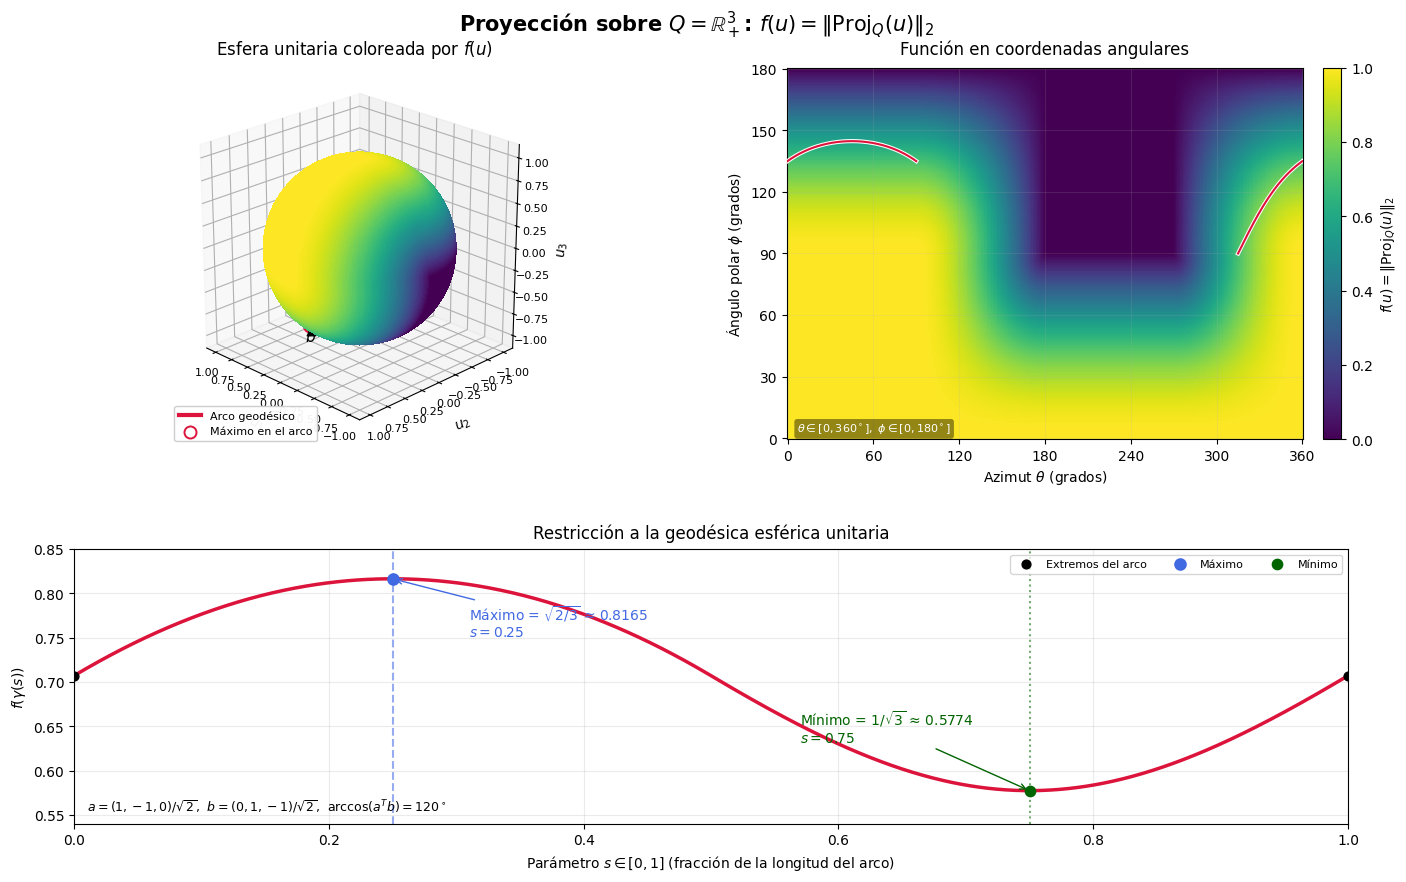

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# ------------------------------------------------------------
# Q = R^3_+ and f(u) = ||Proj_Q(u)|| = ||max(u, 0)||, ||u||=1
# Sphere parametrization: u(theta, phi)=(sin(phi)cos(theta),
# sin(phi)sin(theta), cos(phi)), theta in [0,2pi], phi in [0,pi].
# ------------------------------------------------------------

def proj_norm(U):
    return np.linalg.norm(np.maximum(U, 0.0), axis=-1)

# Angular grid for the entire unit sphere
theta = np.linspace(0, 2*np.pi, 361)
phi = np.linspace(0, np.pi, 181)
TH, PH = np.meshgrid(theta, phi)
X = np.sin(PH) * np.cos(TH)
Y = np.sin(PH) * np.sin(TH)
Z = np.cos(PH)
F = proj_norm(np.stack([X, Y, Z], axis=-1))

# Normalized endpoint vectors and shortest spherical geodesic arc
a = np.array([1.0, -1.0, 0.0]) / np.sqrt(2)
b = np.array([0.0, 1.0, -1.0]) / np.sqrt(2)
alpha = np.arccos(np.clip(np.dot(a, b), -1.0, 1.0))  # 2*pi/3
s = np.linspace(0.0, 1.0, 1001)
t = alpha * s
gamma = (np.sin(alpha - t)[:, None] / np.sin(alpha)) * a + (np.sin(t)[:, None] / np.sin(alpha)) * b
fg = proj_norm(gamma)

imax = int(np.argmax(fg))
smax, fmax = s[imax], fg[imax]
tmin = float(s[np.argmin(fg)])
fmin = float(np.min(fg))

# Plot styling
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'figure.titlesize': 15,
})
fig = plt.figure(figsize=(14, 9), constrained_layout=False)
fig.suptitle(r"Proyección sobre $Q=\mathbb{R}^3_+$: $f(u)=\|\mathrm{Proj}_Q(u)\|_2$", fontweight='bold', y=0.975)
gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 0.85], left=0.055, right=0.965,
                      bottom=0.07, top=0.91, wspace=0.27, hspace=0.34)

norm = colors.Normalize(vmin=0, vmax=1)
cmap = cm.viridis

# 1) Sphere colored by f(u)
ax1 = fig.add_subplot(gs[0, 0], projection='3d')
Ff = (F[:-1, :-1] + F[1:, :-1] + F[:-1, 1:] + F[1:, 1:]) / 4
facecolors = cmap(norm(Ff))
ax1.plot_surface(X, Y, Z, facecolors=facecolors, rstride=1, cstride=1,
                linewidth=0, antialiased=False, shade=False)
# Slightly offset the curve from the sphere to make it visible over the surface
arc_draw = 1.008 * gamma
ax1.plot(arc_draw[:, 0], arc_draw[:, 1], arc_draw[:, 2], color='crimson', linewidth=3.0,
         label='Arco geodésico')
ax1.scatter(*a, color='black', s=38, marker='o', depthshade=False)
ax1.scatter(*b, color='black', s=38, marker='^', depthshade=False)
ax1.scatter(*arc_draw[imax], color='white', edgecolor='crimson', linewidth=1.4,
            s=75, depthshade=False, label='Máximo en el arco')
ax1.text(*(a*1.13), r'$a$', color='black', fontsize=11)
ax1.text(*(b*1.13), r'$b$', color='black', fontsize=11)
ax1.set_title('Esfera unitaria coloreada por $f(u)$', pad=10)
ax1.set_xlabel('$u_1$', labelpad=0); ax1.set_ylabel('$u_2$', labelpad=0); ax1.set_zlabel('$u_3$', labelpad=0)
ax1.set_box_aspect((1, 1, 1))
ax1.view_init(elev=23, azim=135)
ax1.legend(loc='lower left', bbox_to_anchor=(0.0, -0.02), fontsize=8, framealpha=0.95)
ax1.tick_params(labelsize=8, pad=0)

# 2) Angular parameterization heatmap
ax2 = fig.add_subplot(gs[0, 1])
mesh = ax2.pcolormesh(np.degrees(TH), np.degrees(PH), F, shading='auto', cmap=cmap, norm=norm)
ax2.set_title('Función en coordenadas angulares', pad=10)
ax2.set_xlabel(r'Azimut $\theta$ (grados)')
ax2.set_ylabel(r'Ángulo polar $\phi$ (grados)')
ax2.set_xticks(np.arange(0, 361, 60))
ax2.set_yticks(np.arange(0, 181, 30))
ax2.grid(alpha=0.15)
# Arc coordinates on the angular chart. Split where azimuth wraps from 360° to 0°.
th_arc = np.mod(np.degrees(np.arctan2(gamma[:, 1], gamma[:, 0])), 360)
ph_arc = np.degrees(np.arccos(np.clip(gamma[:, 2], -1, 1)))
jumps = np.where(np.abs(np.diff(th_arc)) > 180)[0]
starts = np.r_[0, jumps + 1]
ends = np.r_[jumps + 1, len(s)]
for st, en in zip(starts, ends):
    if en - st > 1:
        ax2.plot(th_arc[st:en], ph_arc[st:en], color='white', linewidth=3.0, zorder=4)
        ax2.plot(th_arc[st:en], ph_arc[st:en], color='crimson', linewidth=1.5, zorder=5)
ax2.text(0.02, 0.02, r'$\theta\in[0,360^\circ],\;\phi\in[0,180^\circ]$',
         transform=ax2.transAxes, fontsize=8, color='white',
         bbox=dict(facecolor='black', alpha=0.42, edgecolor='none', boxstyle='round,pad=0.25'))
cb = fig.colorbar(mesh, ax=ax2, fraction=0.045, pad=0.035)
cb.set_label(r'$f(u)=\|\mathrm{Proj}_Q(u)\|_2$')

# 3) Objective along geodesic
ax3 = fig.add_subplot(gs[1, :])
ax3.plot(s, fg, color='crimson', linewidth=2.5)
ax3.scatter([0, 1], [fg[0], fg[-1]], color='black', s=40, zorder=4, label='Extremos del arco')
ax3.scatter([smax], [fmax], color='royalblue', s=65, zorder=5, label='Máximo')
ax3.scatter([tmin], [fmin], color='darkgreen', s=55, zorder=5, label='Mínimo')
ax3.axvline(smax, color='royalblue', linestyle='--', alpha=0.55)
ax3.axvline(tmin, color='darkgreen', linestyle=':', alpha=0.55)
ax3.set_title('Restricción a la geodésica esférica unitaria', pad=8)
ax3.set_xlabel(r'Parámetro $s\in[0,1]$ (fracción de la longitud del arco)')
ax3.set_ylabel(r'$f(\gamma(s))$')
ax3.grid(True, alpha=0.25)
ax3.set_xlim(0, 1)
ax3.set_ylim(0.54, 0.85)
ax3.legend(loc='upper right', ncol=3, fontsize=8)
ax3.annotate(f'Máximo = $\\sqrt{{2/3}}$ ≈ {fmax:.4f}\n$s={smax:.2f}$', xy=(smax, fmax),
             xytext=(smax+0.06, fmax-0.065),
             arrowprops=dict(arrowstyle='->', color='royalblue'), color='royalblue')
ax3.annotate(f'Mínimo = $1/\\sqrt{{3}}$ ≈ {fmin:.4f}\n$s={tmin:.2f}$', xy=(tmin, fmin),
             xytext=(tmin-0.18, fmin+0.055),
             arrowprops=dict(arrowstyle='->', color='darkgreen'), color='darkgreen')
ax3.text(0.01, 0.03,
         r'$a=(1,-1,0)/\sqrt{2}$,  $b=(0,1,-1)/\sqrt{2}$,  $\arccos(a^Tb)=120^\circ$',
         transform=ax3.transAxes, fontsize=9, va='bottom')

# out = '/mnt/data/funcion_proyeccion_ortante_esfera_geodesia.png'
# fig.savefig(out, dpi=220, bbox_inches='tight', facecolor='white')
print('saved', out)
print('a =', a)
print('b =', b)
print('alpha degrees =', np.degrees(alpha))
print('max arc f =', fmax, 'at s =', smax, 'gamma =', gamma[imax])
print('min arc f =', fmin, 'at s =', tmin)
print('endpoints f =', fg[0], fg[-1])


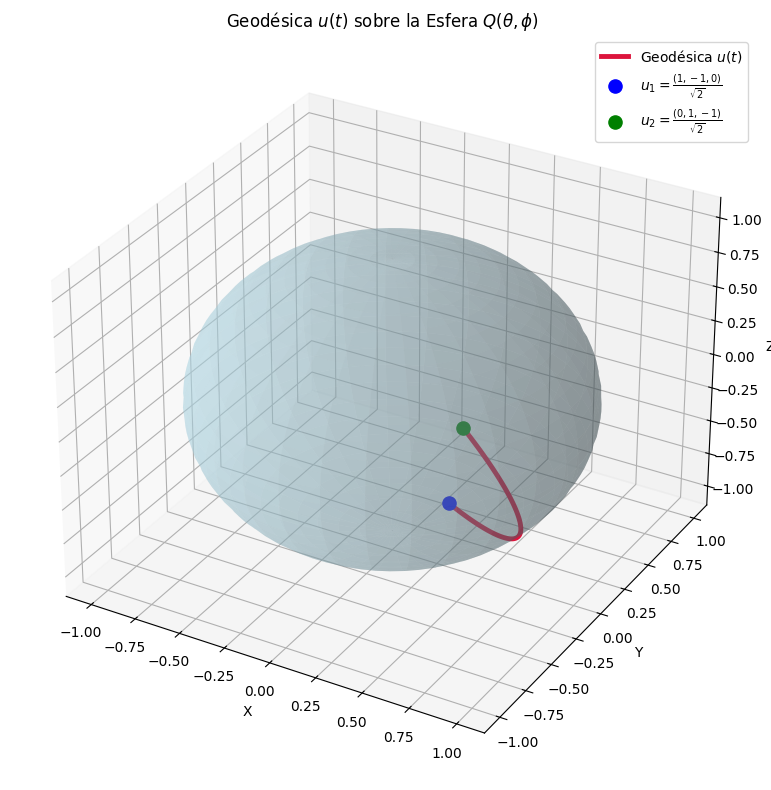

In [39]:
import matplotlib.pyplot as plt
import numpy as np


def generar_geodesica_y_esfera():
    # 1. Definición de puntos inicial y final
    u1 = np.array([1, -1, 0]) / np.sqrt(2)
    u2 = np.array([0, 1, -1]) / np.sqrt(2)

    # 2. Parametrización de la Esfera Q con 2 ángulos (theta, phi)
    theta = np.linspace(0, np.pi, 60)
    phi = np.linspace(0, 2 * np.pi, 60)
    THETA, PHI = np.meshgrid(theta, phi)

    X_Q = np.sin(THETA) * np.cos(PHI)
    Y_Q = np.sin(THETA) * np.sin(PHI)
    Z_Q = np.cos(THETA)

    # 3. Geodésica u(t) sobre la esfera vía SLERP (t en [0, 1])
    cos_omega = np.dot(u1, u2)
    omega = np.arccos(np.clip(cos_omega, -1.0, 1.0))

    t = np.linspace(0, 1, 100)
    sin_omega = np.sin(omega)

    u_t = (
        np.sin((1 - t)[:, None] * omega) * u1 + np.sin(t[:, None] * omega) * u2
    ) / sin_omega

    # 4. Visualización 3D
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    # Superficie Q
    ax.plot_surface(
        X_Q, Y_Q, Z_Q, color='lightblue', alpha=0.35, edgecolor='none'
    )

    # Curva de la geodésica u(t)
    ax.plot(
        u_t[:, 0],
        u_t[:, 1],
        u_t[:, 2],
        color='crimson',
        linewidth=3.5,
        label='Geodésica $u(t)$',
    )

    # Puntos u1 y u2
    ax.scatter(
        u1[0],
        u1[1],
        u1[2],
        color='blue',
        s=90,
        zorder=5,
        label=r'$u_1 = \frac{(1,-1,0)}{\sqrt{2}}$',
    )
    ax.scatter(
        u2[0],
        u2[1],
        u2[2],
        color='green',
        s=90,
        zorder=5,
        label=r'$u_2 = \frac{(0,1,-1)}{\sqrt{2}}$',
    )

    # Configuración de ejes
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title('Geodésica $u(t)$ sobre la Esfera $Q(\\theta, \\phi)$')
    ax.legend(loc='upper right')

    plt.tight_layout()
    plt.show()


if __name__ == '__main__':
    generar_geodesica_y_esfera()

In [40]:
import numpy as np

# 1. Definicion de puntos limite y angulo de separacion
u1 = np.array([1.0, -1.0, 0.0]) / np.sqrt(2)
u2 = np.array([0.0, 1.0, -1.0]) / np.sqrt(2)

cos_omega = np.dot(u1, u2)
omega = np.arccos(np.clip(cos_omega, -1.0, 1.0))

# 2. Parametro t para la geodesica
t_vals = np.linspace(0, 1, 100)
sin_omega = np.sin(omega)

# Componentes cartesiana de u(t) via SLERP
u_t = (
    np.sin((1 - t_vals)[:, None] * omega) * u1
    + np.sin(t_vals[:, None] * omega) * u2
) / sin_omega

# 3. Conversión a parametros angulares theta(t) y phi(t)
theta_t = np.arccos(np.clip(u_t[:, 2], -1.0, 1.0))
phi_t = np.arctan2(u_t[:, 1], u_t[:, 0]) % (2 * np.pi)


# 4. Función de parametrización v(theta, phi)
def v_parametrizada(theta, phi):
    return np.array(
        [
            np.sin(theta) * np.cos(phi),
            np.sin(theta) * np.sin(phi),
            np.cos(theta),
        ]
    )


# 5. Verificación de Proj_Q(u) y norma
proyecciones = []
normas_proj = []

for i in range(len(t_vals)):
    # El punto v en Q que minimiza ||v - u(t)|| es v(theta(t), phi(t))
    proj_u = v_parametrizada(theta_t[i], phi_t[i])
    proyecciones.append(proj_u)
    normas_proj.append(np.linalg.norm(proj_u))

normas_proj = np.array(normas_proj)

print(f"Ángulo total de la geodésica Omega: {np.degrees(omega):.2f}°")
print(
    f"Ángulos iniciales (t=0): theta = {np.degrees(theta_t[0]):.2f}°, phi = {np.degrees(phi_t[0]):.2f}°"
)
print(
    f"Ángulos finales   (t=1): theta = {np.degrees(theta_t[-1]):.2f}°, phi = {np.degrees(phi_t[-1]):.2f}°"
)
print(f"Valor constante de F(u) = ||Proj_Q(u)||: {np.mean(normas_proj):.6f}")

Ángulo total de la geodésica Omega: 120.00°
Ángulos iniciales (t=0): theta = 90.00°, phi = 315.00°
Ángulos finales   (t=1): theta = 135.00°, phi = 90.00°
Valor constante de F(u) = ||Proj_Q(u)||: 1.000000


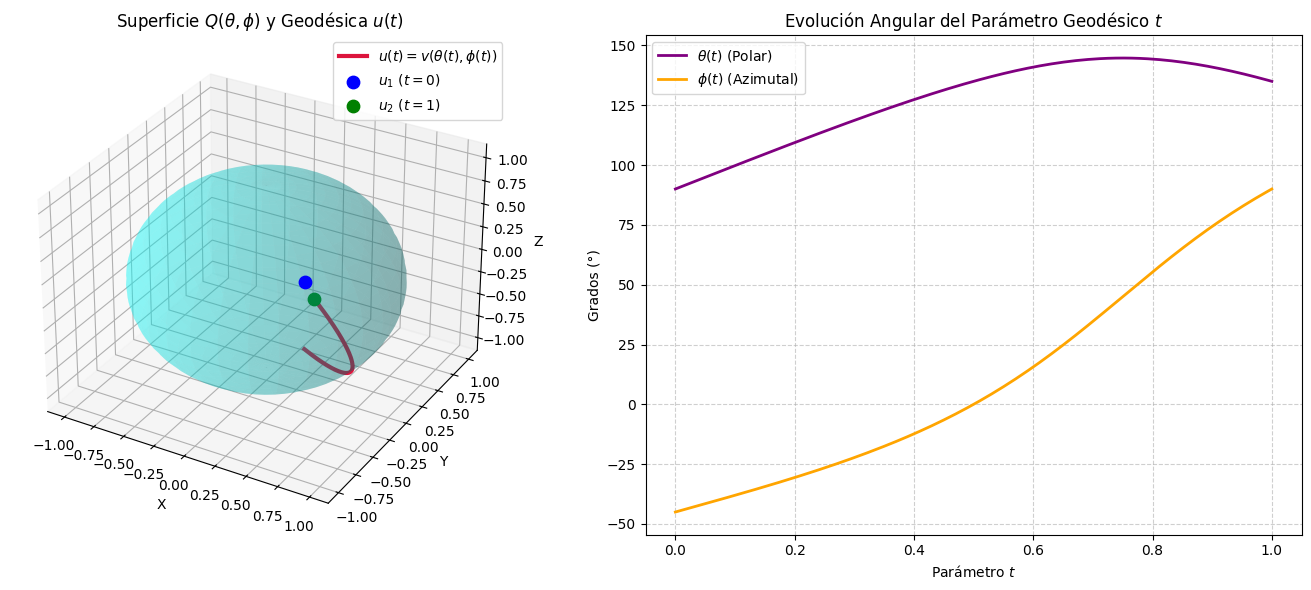

In [41]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Puntos y Geodésica
u1 = np.array([1.0, -1.0, 0.0]) / np.sqrt(2)
u2 = np.array([0.0, 1.0, -1.0]) / np.sqrt(2)

cos_omega = np.dot(u1, u2)
omega = np.arccos(np.clip(cos_omega, -1.0, 1.0))

t = np.linspace(0, 1, 150)
u_t = (
    np.sin((1 - t)[:, None] * omega) * u1 + np.sin(t[:, None] * omega) * u2
) / np.sin(omega)

theta_t = np.arccos(np.clip(u_t[:, 2], -1.0, 1.0))
phi_t = np.unwrap(np.arctan2(u_t[:, 1], u_t[:, 0]))

# 2. Malla 2D para la Esfera Q en función de (theta, phi)
theta_grid = np.linspace(0, np.pi, 60)
phi_grid = np.linspace(0, 2 * np.pi, 60)
THETA, PHI = np.meshgrid(theta_grid, phi_grid)

X_Q = np.sin(THETA) * np.cos(PHI)
Y_Q = np.sin(THETA) * np.sin(PHI)
Z_Q = np.cos(THETA)

# 3. Graficación
fig = plt.figure(figsize=(14, 6))

# Panel 3D
ax1 = fig.add_subplot(121, projection="3d")
ax1.plot_surface(X_Q, Y_Q, Z_Q, color="cyan", alpha=0.25, edgecolor="none")
ax1.plot(
    u_t[:, 0],
    u_t[:, 1],
    u_t[:, 2],
    color="crimson",
    linewidth=3,
    label="$u(t) = v(\\theta(t), \\phi(t))$",
)
ax1.scatter(
    u1[0], u1[1], u1[0], color="blue", s=80, label="$u_1$ ($t=0$)", zorder=5
)
ax1.scatter(
    u2[0], u2[1], u2[2], color="green", s=80, label="$u_2$ ($t=1$)", zorder=5
)

ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.set_title("Superficie $Q(\\theta, \\phi)$ y Geodésica $u(t)$")
ax1.legend()

# Panel 2D: Evolución de los Ángulos
ax2 = fig.add_subplot(122)
ax2.plot(t, np.degrees(theta_t), color="purple", linewidth=2, label="$\\theta(t)$ (Polar)")
ax2.plot(t, np.degrees(phi_t), color="orange", linewidth=2, label="$\\phi(t)$ (Azimutal)")
ax2.set_xlabel("Parámetro $t$")
ax2.set_ylabel("Grados (°)")
ax2.set_title("Evolución Angular del Parámetro Geodésico $t$")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

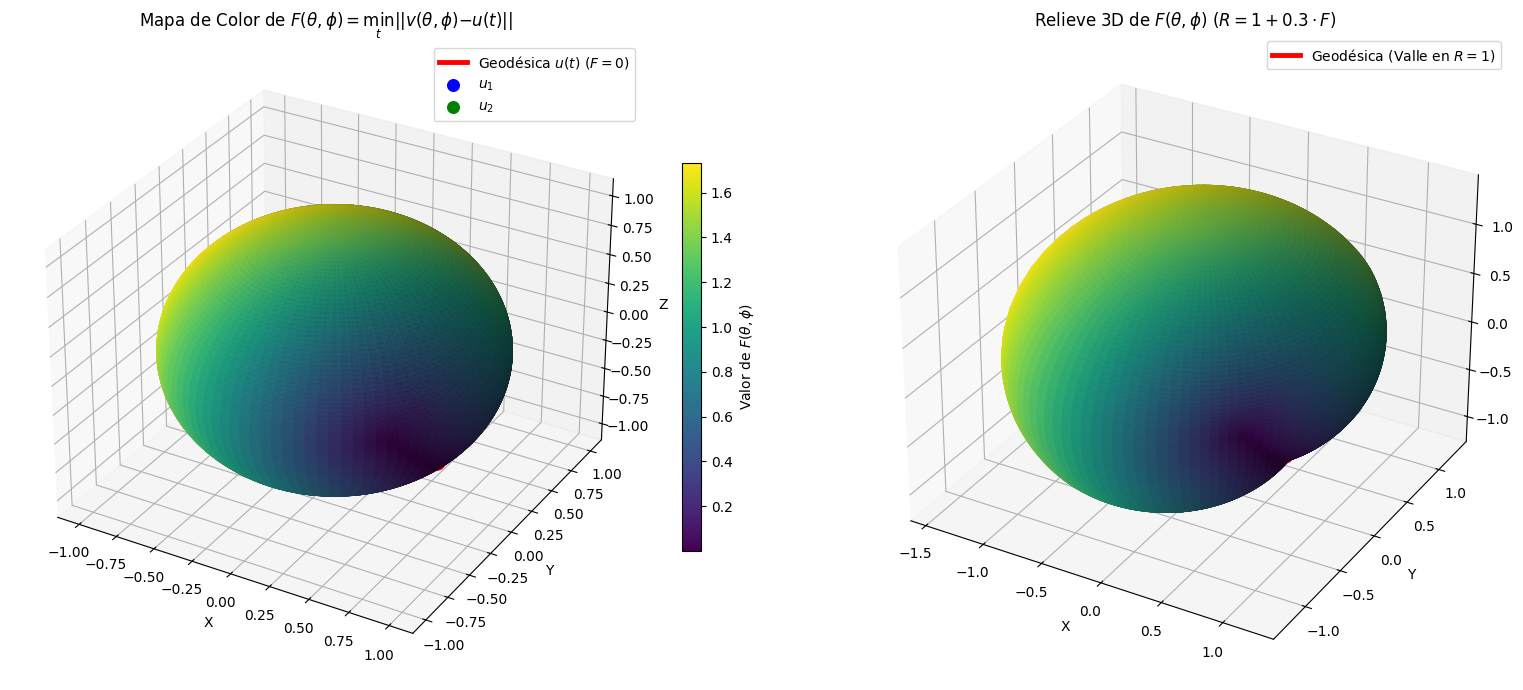

In [42]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Definición de puntos y geodésica u(t)
u1 = np.array([1.0, -1.0, 0.0]) / np.sqrt(2)
u2 = np.array([0.0, 1.0, -1.0]) / np.sqrt(2)

cos_omega = np.dot(u1, u2)
omega = np.arccos(np.clip(cos_omega, -1.0, 1.0))

t_vals = np.linspace(0, 1, 100)
sin_omega = np.sin(omega)
u_t = (
    np.sin((1 - t_vals)[:, None] * omega) * u1
    + np.sin(t_vals[:, None] * omega) * u2
) / sin_omega

# 2. Malla angular en la esfera Q(theta, phi)
theta_grid = np.linspace(0, np.pi, 100)
phi_grid = np.linspace(0, 2 * np.pi, 100)
THETA, PHI = np.meshgrid(theta_grid, phi_grid)

# Coordenadas cartesianas unitarias para cada (theta, phi)
X_Q = np.sin(THETA) * np.cos(PHI)
Y_Q = np.sin(THETA) * np.sin(PHI)
Z_Q = np.cos(THETA)

# 3. Cálculo de F(theta, phi) = min_t ||v(theta, phi) - u(t)||
Q_points = np.stack([X_Q, Y_Q, Z_Q], axis=-1)  # Forma (100, 100, 3)

# Distancia broadcast entre cada punto (theta, phi) y todos los puntos u(t)
diferencias = Q_points[:, :, None, :] - u_t[None, None, :, :]
distancias = np.linalg.norm(diferencias, axis=-1)
F_theta_phi = np.min(distancias, axis=-1)

# 4. Configuración de figuras 3D
fig = plt.figure(figsize=(16, 7))

# --- GRÁFICO 1: Mapa de Color 3D de F(theta, phi) sobre la Esfera ---
ax1 = fig.add_subplot(121, projection='3d')

# Normalización de color basada en F(theta, phi)
norm = plt.Normalize(F_theta_phi.min(), F_theta_phi.max())
colors = plt.cm.viridis(norm(F_theta_phi))

surf1 = ax1.plot_surface(
    X_Q, Y_Q, Z_Q, facecolors=colors, rstride=1, cstride=1, alpha=0.85, antialiased=True
)

# Trazado de la geodésica u(t) sobre la superficie
ax1.plot(
    u_t[:, 0],
    u_t[:, 1],
    u_t[:, 2],
    color='red',
    linewidth=3.5,
    label='Geodésica $u(t)$ ($F=0$)',
)
ax1.scatter(u1[0], u1[1], u1[2], color='blue', s=70, label='$u_1$')
ax1.scatter(u2[0], u2[1], u2[2], color='green', s=70, label='$u_2$')

ax1.set_title('Mapa de Color de $F(\\theta, \\phi) = \\min_{t} ||v(\\theta,\\phi) - u(t)||$')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')
ax1.legend(loc='upper right')

# Barra de color para F
mappable = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
mappable.set_array(F_theta_phi)
fig.colorbar(mappable, ax=ax1, shrink=0.6, label='Valor de $F(\\theta, \\phi)$')

# --- GRÁFICO 2: Superficie 3D Deformada en Radio (Relieve de F) ---
ax2 = fig.add_subplot(122, projection='3d')

# Escala de deformación radial: R(theta, phi) = 1 + 0.3 * F(theta, phi)
factor_deformacion = 0.3
R = 1.0 + factor_deformacion * F_theta_phi

X_def = R * np.sin(THETA) * np.cos(PHI)
Y_def = R * np.sin(THETA) * np.sin(PHI)
Z_def = R * np.cos(THETA)

surf2 = ax2.plot_surface(
    X_def, Y_def, Z_def, facecolors=colors, rstride=1, cstride=1, alpha=0.9, antialiased=True
)

ax2.plot(
    u_t[:, 0],
    u_t[:, 1],
    u_t[:, 2],
    color='red',
    linewidth=3.5,
    label='Geodésica (Valle en $R=1$)',
)

ax2.set_title('Relieve 3D de $F(\\theta, \\phi)$ ($R = 1 + 0.3 \\cdot F$)')
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('Z')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

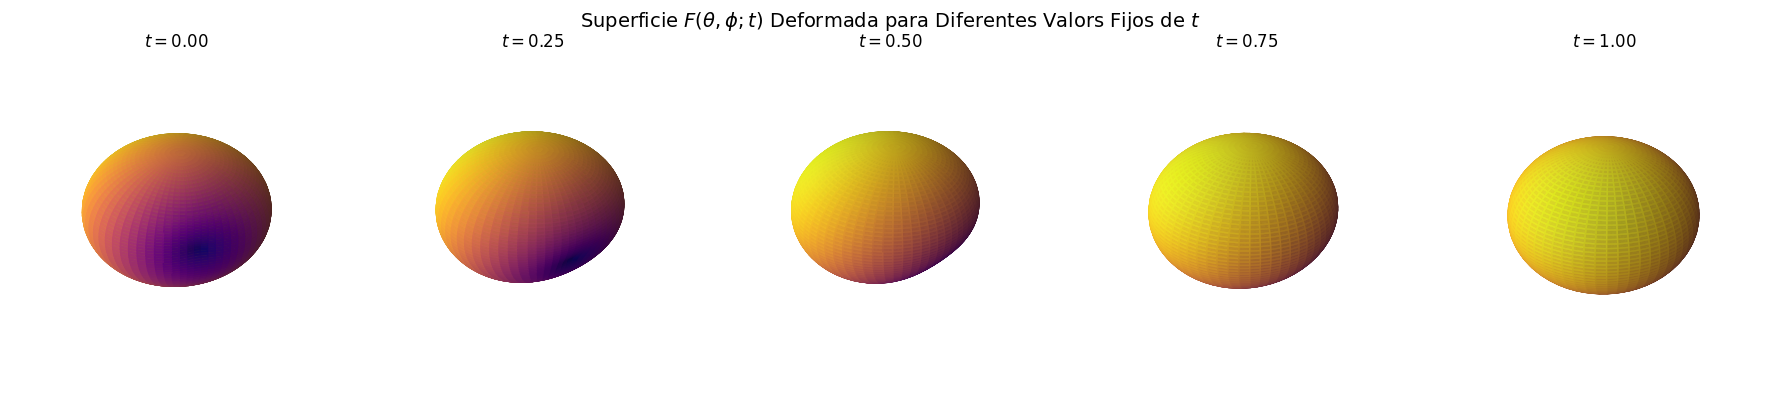

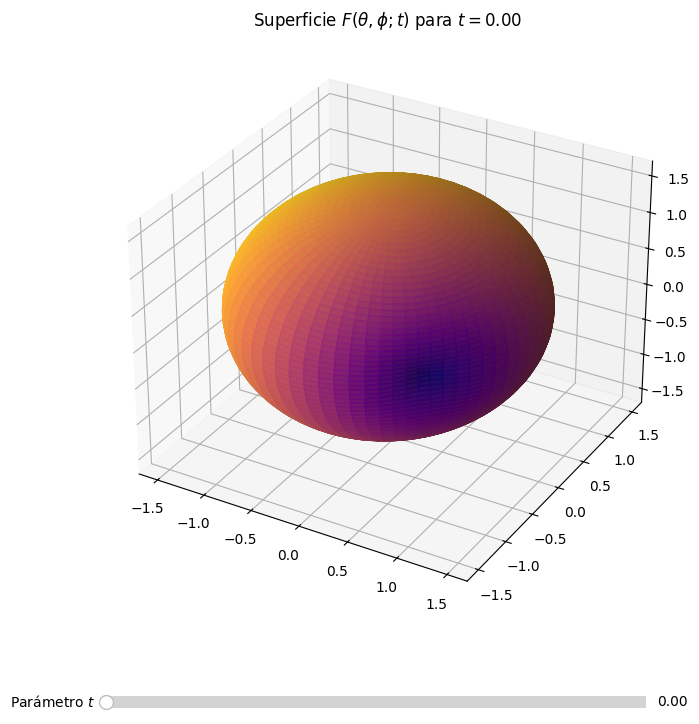

In [44]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Geodésica y Esfera
u1 = np.array([1.0, -1.0, 0.0]) / np.sqrt(2)
u2 = np.array([0.0, 1.0, -1.0]) / np.sqrt(2)
cos_omega = np.dot(u1, u2)
omega = np.arccos(np.clip(cos_omega, -1.0, 1.0))

# Malla angular (theta, phi)
theta_grid = np.linspace(0, np.pi, 60)
phi_grid = np.linspace(0, 2 * np.pi, 60)
THETA, PHI = np.meshgrid(theta_grid, phi_grid)

# Vectores unitarios de la esfera base Q
V_x = np.sin(THETA) * np.cos(PHI)
V_y = np.sin(THETA) * np.sin(PHI)
V_z = np.cos(THETA)
V_pts = np.stack([V_x, V_y, V_z], axis=-1)

# Valors fijos de t
t_valores = [0.0, 0.25, 0.50, 0.75, 1.00]
factor_deformacion = 0.35

fig = plt.figure(figsize=(18, 4))

for idx, t0 in enumerate(t_valores):
    # Punto u(t0) fijo
    u_t0 = (
        np.sin((1 - t0) * omega) * u1 + np.sin(t0 * omega) * u2
    ) / np.sin(omega)

    # Distancia F_t0(theta, phi)
    F_t0 = np.linalg.norm(V_pts - u_t0, axis=-1)

    # Superficie deformada R(theta, phi) = 1 + c * F_t0
    R = 1.0 + factor_deformacion * F_t0
    X_def = R * V_x
    Y_def = R * V_y
    Z_def = R * V_z

    # Normalización de color
    norm = plt.Normalize(0, 2)
    colors = plt.cm.plasma(norm(F_t0))

    ax = fig.add_subplot(1, 5, idx + 1, projection='3d')
    surf = ax.plot_surface(
        X_def,
        Y_def,
        Z_def,
        facecolors=colors,
        rstride=1,
        cstride=1,
        alpha=0.9,
        antialiased=True,
    )

    # Marcar el punto u(t0) exacto
    ax.scatter(
        u_t0[0],
        u_t0[1],
        u_t0[2],
        color='cyan',
        s=80,
        zorder=5,
        edgecolor='black',
    )

    ax.set_title(f'$t = {t0:.2f}$')
    ax.set_xlim([-1.7, 1.7])
    ax.set_ylim([-1.7, 1.7])
    ax.set_zlim([-1.7, 1.7])
    ax.axis('off')

plt.suptitle(
    'Superficie $F(\\theta, \\phi; t)$ Deformada para Diferentes Valors Fijos de $t$',
    fontsize=14,
)
plt.tight_layout()
plt.show()
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.widgets import Slider

# 1. Parámetros Geodésicos
u1 = np.array([1.0, -1.0, 0.0]) / np.sqrt(2)
u2 = np.array([0.0, 1.0, -1.0]) / np.sqrt(2)
omega = np.arccos(np.clip(np.dot(u1, u2), -1.0, 1.0))

# Malla (theta, phi)
theta_grid = np.linspace(0, np.pi, 60)
phi_grid = np.linspace(0, 2 * np.pi, 60)
THETA, PHI = np.meshgrid(theta_grid, phi_grid)

V_x = np.sin(THETA) * np.cos(PHI)
V_y = np.sin(THETA) * np.sin(PHI)
V_z = np.cos(THETA)
V_pts = np.stack([V_x, V_y, V_z], axis=-1)

c = 0.35  # Factor de deformación radial


# Función para calcular coordenadas y colores dado un t0
def calcular_superficie(t0):
    u_t0 = (
        np.sin((1 - t0) * omega) * u1 + np.sin(t0 * omega) * u2
    ) / np.sin(omega)
    F_t0 = np.linalg.norm(V_pts - u_t0, axis=-1)
    R = 1.0 + c * F_t0
    X = R * V_x
    Y = R * V_y
    Z = R * V_z
    colors = plt.cm.plasma(F_t0 / 2.0)
    return X, Y, Z, colors, u_t0


# 2. Configuración de la Figura e Interfaz
fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection='3d')
plt.subplots_adjust(bottom=0.15)

# Renderizado inicial para t = 0
t_init = 0.0
X, Y, Z, colors, u_t0 = calcular_superficie(t_init)

surf = [
    ax.plot_surface(
        X, Y, Z, facecolors=colors, rstride=1, cstride=1, alpha=0.9
    )
]
point = [
    ax.scatter(
        u_t0[0],
        u_t0[1],
        u_t0[2],
        color='cyan',
        s=100,
        zorder=5,
        edgecolor='black',
    )
]

ax.set_xlim([-1.7, 1.7])
ax.set_ylim([-1.7, 1.7])
ax.set_zlim([-1.7, 1.7])
ax.set_title(f'Superficie $F(\\theta, \\phi; t)$ para $t = {t_init:.2f}$')

# 3. Slider Interactivo
ax_t = plt.axes([0.2, 0.03, 0.6, 0.03])
slider_t = Slider(
    ax_t,
    'Parámetro $t$',
    0.0,
    1.0,
    valinit=t_init,
    valfmt='%.2f',
    color='purple',
)


def actualizar(val):
    t_val = slider_t.val
    X_new, Y_new, Z_new, colors_new, u_new = calcular_superficie(t_val)

    surf[0].remove()
    point[0].remove()

    surf[0] = ax.plot_surface(
        X_new, Y_new, Z_new, facecolors=colors_new, rstride=1, cstride=1, alpha=0.9
    )
    point[0] = ax.scatter(
        u_new[0],
        u_new[1],
        u_new[2],
        color='cyan',
        s=100,
        zorder=5,
        edgecolor='black',
    )
    ax.set_title(f'Superficie $F(\\theta, \\phi; t)$ para $t = {t_val:.2f}$')
    fig.canvas.draw_idle()


slider_t.on_changed(actualizar)

plt.show()


In [65]:
import numpy as np
from scipy.optimize import nnls
import time

def proj_cone(G, u):
    """
    Proyecta el vector u sobre el cono convexo P = cone(G)
    mediante mínimos cuadrados no negativos (equivalente a lsqnonneg en MATLAB).
    """
    x, _ = nnls(G, u)
    return G @ x
def sphere_param(theta, phi):
    """
    Parametrización de la esfera unitaria en R^3 usando coordenadas esféricas.
    theta: ángulo polar [0, pi]
    phi: ángulo azimutal [0, 2*pi]
    """
    x = np.sin(theta) * np.cos(phi)
    y = np.sin(theta) * np.sin(phi)
    z = np.cos(theta)
    return np.array([x, y, z])

def funcion(theta, phi, G):
    """
    Función objetivo f(u) = ||Proj_Q(u)||_2 donde Q = R^3_+.
    """

    u = sphere_param(theta, phi)
    if np.any(u < 0):
        return max(u) # Si algún componente es negativo, la proyección es cero
    else:
        proj_u = proj_cone(G, u)
    return np.linalg.norm(proj_u)

G = np.eye(3)
f = lambda theta, phi: funcion(theta, phi, G)



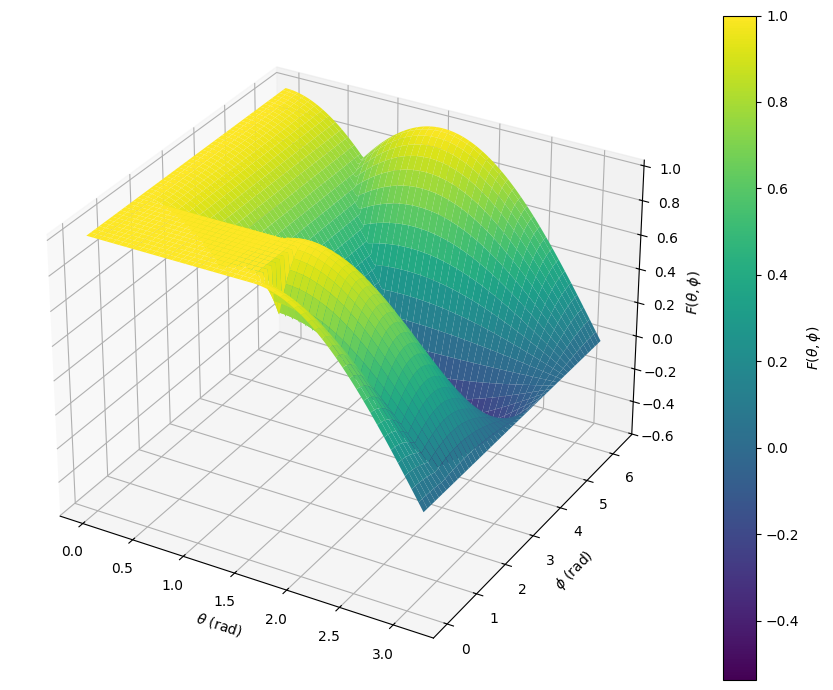

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import nnls
import time

def proj_cone(G, u):
    """
    Proyecta el vector u sobre el cono convexo P = cone(G)
    mediante mínimos cuadrados no negativos (equivalente a lsqnonneg en MATLAB).
    """
    x, _ = nnls(G, u)
    return G @ x
def sphere_param(theta, phi):
    """
    Parametrización de la esfera unitaria en R^3 usando coordenadas esféricas.
    theta: ángulo polar [0, pi]
    phi: ángulo azimutal [0, 2*pi]
    """
    x = np.sin(theta) * np.cos(phi)
    y = np.sin(theta) * np.sin(phi)
    z = np.cos(theta)
    return np.array([x, y, z])

def funcion(theta, phi, G):
    """
    Función objetivo f(u) = ||Proj_Q(u)||_2 donde Q = R^3_+.
    """

    u = sphere_param(theta, phi)
    if np.any(u < 0):
        return max(u) # Si algún componente es negativo, la proyección es cero
    else:
        proj_u = proj_cone(G, u)
    return np.linalg.norm(proj_u)

G = np.eye(3)
f = lambda theta, phi: funcion(theta, phi, G)


# Parámetros angulares
theta = np.linspace(0, np.pi, 200)
phi = np.linspace(0, 2*np.pi, 200)

A, B = np.meshgrid(theta, phi)

# Evaluar la función en cada par de ángulos
F = np.zeros_like(A)

for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        F[i, j] = funcion(A[i, j], B[i, j], G)

# Gráfica 3D
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(A, B, F, cmap='viridis', edgecolor='none')

fig.colorbar(surf, ax=ax, label=r'$F(\theta,\phi)$')

ax.set_xlabel(r'$\theta$ (rad)')
ax.set_ylabel(r'$\phi$ (rad)')
ax.set_zlabel(r'$F(\theta,\phi)$')
# ax.set_title(r'$F(\theta,\phi)=\|\operatorname{Proj}_{\operatorname{cone}(G)}(u)\|$')

plt.tight_layout()
plt.show()